# Group D: Information Retrieval 

!pip install nltk scikit-learn pandas matplotlib


## 1: Text preprocessing – stop-word removal and stemming

In [12]:
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re

text = "The students are learning information retrieval and searching for documents."

words = text.lower().split()
filtered_words = [word for word in words if word not in ENGLISH_STOP_WORDS]

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]

print("Original Text:", text)
print("After Stop-word Removal:", filtered_words)
print("After Stemming:", stemmed_words)

Original Text: The students are learning information retrieval and searching for documents.
After Stop-word Removal: ['students', 'learning', 'information', 'retrieval', 'searching', 'documents.']
After Stemming: ['student', 'learn', 'inform', 'retriev', 'search', 'documents.']


## 2: Document retrieval using an inverted index

In [ ]:
# Documents
documents = {
    "D1": "Python is easy to learn",
    "D2": "Machine learning is interesting",
    "D3": "Python is used in machine learning"
}


# Create inverted index
inverted_index = {}


for doc_id, text in documents.items():
    words = text.lower().split()

    for word in words:
        if word not in inverted_index:
            inverted_index[word] = []

        if doc_id not in inverted_index[word]:
            inverted_index[word].append(doc_id)


# Display inverted index
print("Inverted Index:")
print(inverted_index)


# Search for a word
search_word = input("\nEnter a word to search: ").lower()

if search_word in inverted_index:
    print("Documents found:", inverted_index[search_word])
else:
    print("No documents found")

Inverted Index:
information : ['doc1.txt', 'doc2.txt']
retrieval : ['doc1.txt']
is : ['doc1.txt', 'doc3.txt']
the : ['doc1.txt']
process : ['doc1.txt']
of : ['doc1.txt']
finding : ['doc1.txt']
useful : ['doc1.txt']
from : ['doc1.txt']
a : ['doc1.txt', 'doc3.txt', 'doc2.txt']
collection : ['doc1.txt']
documents : ['doc1.txt', 'doc3.txt', 'doc2.txt']
search : ['doc1.txt', 'doc2.txt']
engines : ['doc1.txt']
help : ['doc1.txt']
users : ['doc1.txt', 'doc2.txt']
find : ['doc1.txt', 'doc2.txt']
relevant : ['doc1.txt']
quickly : ['doc1.txt']
an : ['doc1.txt']
inverted : ['doc1.txt']
index : ['doc1.txt']
used : ['doc1.txt', 'doc3.txt']
in : ['doc1.txt', 'doc2.txt']
systems : ['doc1.txt']
python : ['doc3.txt']
popular : ['doc3.txt']
programming : ['doc3.txt']
language : ['doc3.txt']
can : ['doc3.txt', 'doc2.txt']
be : ['doc3.txt', 'doc2.txt']
for : ['doc3.txt']
text : ['doc3.txt']
processing : ['doc3.txt']
and : ['doc3.txt', 'doc2.txt']
data : ['doc3.txt']
analysis : ['doc3.txt']
contain : ['doc

## 3: E-mail spam filtering using text classification

A small sample dataset is included, so no external dataset download is needed.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Load dataset
data = pd.read_csv("spam_ham_dataset.csv")

# Select email text and labels
X = data["text"]
y = data["label"]

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Convert text into numerical features
vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

# Train Naive Bayes classifier
model = MultinomialNB()
model.fit(X_train, y_train)

# Test the model
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

# Predict a new email
email = ["Congratulations! You have won a free prize. Click here."]
email = vectorizer.transform(email)

print("Email Prediction:", model.predict(email)[0])

Accuracy: 0.9719806763285024
Email Prediction: spam


## 4: Agglomerative hierarchical clustering

The Iris dataset is used to form three clusters.

Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


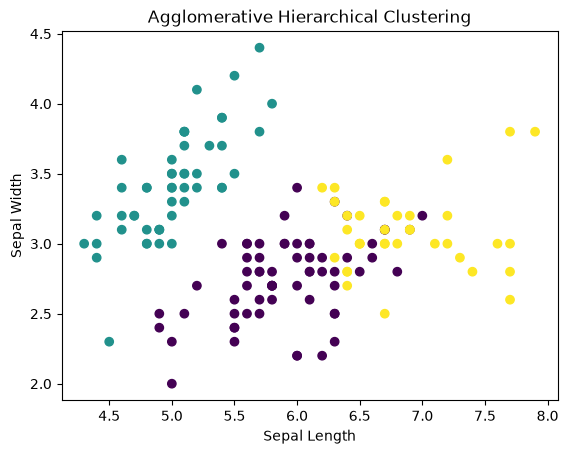

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

# Load Mall Customers dataset
data = pd.read_csv("Mall_Customers.csv")

# Select numerical features
X = data[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]

# Apply Agglomerative Hierarchical Clustering
model = AgglomerativeClustering(n_clusters=5, linkage="ward")
clusters = model.fit_predict(X)

# Display cluster labels
print("Cluster Labels:")
print(clusters)

# Plot the clusters
plt.scatter(X["Annual Income (k$)"],
            X["Spending Score (1-100)"],
            c=clusters)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Agglomerative Hierarchical Clustering")
plt.show()

## 5: PageRank algorithm

In [5]:
graph = {
    "A": ["B", "C"],
    "B": ["C"],
    "C": ["A"],
    "D": ["C"]
}

pages = list(graph.keys())
N = len(pages)
damping = 0.85

rank = {page: 1 / N for page in pages}

for iteration in range(10):
    new_rank = {}

    for page in pages:
        incoming_rank = 0

        for other_page in pages:
            if page in graph[other_page]:
                incoming_rank += rank[other_page] / len(graph[other_page])

        new_rank[page] = (1 - damping) / N + damping * incoming_rank

    rank = new_rank

print("PageRank:")
for page, score in rank.items():
    print(page, ":", round(score, 4))

print("\nPages ranked from highest to lowest:")
print(sorted(rank.items(), key=lambda item: item[1], reverse=True))

PageRank:
A : 0.3751
B : 0.1949
C : 0.3925
D : 0.0375

Pages ranked from highest to lowest:
[('C', 0.3925085588565621), ('A', 0.375054382302053), ('B', 0.1949370588413849), ('D', 0.037500000000000006)]
